# Introdution
   

In this project we will be predicting the residential property values using the data available from Property Services Regulatory Authority (PSRA) Residential Property Price Register (property_price_register.csv). County Sligo was chosen since it maintains the data homogeneous (same local market) and the dataset a reasonable size (about 11,000 sales), considerably beyond the 300 rows required. Otherwise prices would be dominated by county-level differences (e.g. Dublin vs Sligo). It would also make the study more difficult if we used all the observations in the data set. A regression technique will be used and three models will be compared: linear regression, decision tree and random forest.

# 1. Import Libraries

Libraries were imported to support data cleaning, analysis, visualisation, and Machine Learning to predict the target: House price in the county of Sligo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, median_absolute_error, mean_squared_error



# 2. Data Loading and  data exploration
The dataset was imported using Pandas and called df_counts (counts of Ireland).

In order to take out the DtypeWarning Low memory because was used.

In [2]:
df_counts= pd.read_csv('property_price_register.csv', low_memory=False)

Check the first 5 observations of the dataset. Here we can see the county, price, description, date of sale, and other columns. The head() function was used to confirm that the dataset has loaded correctly.

In [3]:
df_counts.head()

,date_of_sale,address,county,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size
0,2010-01-01,"5 Braemor Drive, Churchtown, Co.Dublin",Dublin,NaN,343000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
1,2010-01-03,"134 Ashewood Walk, Summerhill Lane, Portlaoise",Laois,NaN,185000.0,False,True,New Dwelling house /Apartment,greater than or equal to 38 sq metres and less...
2,2010-01-04,"59 ormond keep, nenagh",Tipperary,NaN,128000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
3,2010-01-04,"66 Rory O'Connor Place, Arklow",Wicklow,NaN,145000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
4,2010-01-04,"78 Sundays Well Road, Cork",Cork,NaN,510000.0,False,False,Second-Hand Dwelling house /Apartment,NaN


The property price register dataset has 807,936 observations and 9 features. As explained earlier, this is the reason why only one county was chosen.

In [4]:
df_counts.shape

(807936, 9)

Here we present all the existing features.

In [5]:
df_counts.columns.tolist()

['date_of_sale',
 'address',
 'county',
 'eircode',
 'price_eur',
 'not_full_market_price',
 'vat_exclusive',
 'description',
 'property_size']

Here we can verify the 807,936 observations across 9 features. Any count below that number indicates missing values. For example, eircode has 251,432 entries and property_size has 52,608  entries instead of 807,936 entries, which means both features have a large number of missing values. 

This output also shows the data types: six features are stored as strings (object), one as a float, and two as booleans.

In [6]:
df_counts.info()

<class 'pandas.DataFrame'>
RangeIndex: 807936 entries, 0 to 807935
Data columns (total 9 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   date_of_sale           807936 non-null  str    
 1   address                807936 non-null  str    
 2   county                 807936 non-null  str    
 3   eircode                251432 non-null  str    
 4   price_eur              807936 non-null  float64
 5   not_full_market_price  807936 non-null  bool   
 6   vat_exclusive          807936 non-null  bool   
 7   description            807936 non-null  str    
 8   property_size          52608 non-null   str    
dtypes: bool(2), float64(1), str(6)
memory usage: 117.1 MB


As shown in the previous block, eircode has 556,504 missing values and property_size has 755,328. These will be handled in the data cleaning stage, if necessary.

In [7]:
print(df_counts.isnull().sum())

date_of_sale                  0
address                       0
county                        0
eircode                  556504
price_eur                     0
not_full_market_price         0
vat_exclusive                 0
description                   0
property_size            755328
dtype: int64


Before deciding which county to analyse, the value_counts() output was also taken into consideration, as it shows which counties would be the easiest and most manageable to work with. Sligo has 11,751 observations of recorded property sales.

In [8]:
df_counts['county'].value_counts().head(20)

county
Dublin       253128
Cork          89418
Kildare       44108
Galway        38940
Meath         33593
Limerick      29601
Wexford       28232
Wicklow       27316
Louth         22754
Waterford     22129
Kerry         21898
Tipperary     21586
Donegal       21405
Mayo          19209
Clare         18057
Westmeath     15620
Laois         13446
Kilkenny      13050
Cavan         11912
Sligo         11751
Name: count, dtype: int64

# 3. Data cleaning
Filter to just County Sligo (strip spaces and lower-case to avoid mismatches like "Sligo " or "SLIGO".
Also, create a new data frame containing only observations from the county of Sligo, avoiding the loss of important information from the original dataset. 

In [9]:
# copy() creates an independent dataframe, so later changes do not affect df_counts
df = df_counts[df_counts["county"].astype(str).str.strip().str.lower() == "sligo"].copy()


Confirm that only the chosen county will be analysed. 

In [10]:
df["county"].unique()

<ArrowStringArray>
['Sligo']
Length: 1, dtype: str

Check the first 5 rows

In [11]:
df.head()

,date_of_sale,address,county,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size
40,2010-01-04,"4 Hawthorn Court, Collooney",Sligo,NaN,220000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
102,2010-01-06,"25 Markievicz Heights, Sligo",Sligo,NaN,227000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
157,2010-01-08,"Rathquarter, Sligo",Sligo,NaN,12000.0,True,False,Second-Hand Dwelling house /Apartment,NaN
198,2010-01-08,"28 Temple Manor, Balllinacarrow, Co. Sligo",Sligo,NaN,200000.0,False,True,New Dwelling house /Apartment,greater than 125 sq metres
261,2010-01-12,"Kevinsfort Park, Strandhill Road, Sligo",Sligo,NaN,300000.0,True,False,Second-Hand Dwelling house /Apartment,NaN


This output also shows that the data types os Sligo: six features are stored as strings (object), one as a float, and two as booleans.

In [12]:
print(df.dtypes)

date_of_sale                 str
address                      str
county                       str
eircode                      str
price_eur                float64
not_full_market_price       bool
vat_exclusive               bool
description                  str
property_size                str
dtype: object


Any feature with a Non-Null Count lower than  11751 entries has missing values. In this case, remain eircode and property_size 

In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 11751 entries, 40 to 807833
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date_of_sale           11751 non-null  str    
 1   address                11751 non-null  str    
 2   county                 11751 non-null  str    
 3   eircode                3568 non-null   str    
 4   price_eur              11751 non-null  float64
 5   not_full_market_price  11751 non-null  bool   
 6   vat_exclusive          11751 non-null  bool   
 7   description            11751 non-null  str    
 8   property_size          725 non-null    str    
dtypes: bool(2), float64(1), str(6)
memory usage: 1.7 MB


The county sligo has in the eircode 8,183 missing values and in the property_size 11,026 missing values.

In [14]:
print(df.isnull().sum())

date_of_sale                 0
address                      0
county                       0
eircode                   8183
price_eur                    0
not_full_market_price        0
vat_exclusive                0
description                  0
property_size            11026
dtype: int64


The property_size feature has 11,026 missing values out of 11,751 observations (about 93.8%). Because deleting these rows would leave very little data, they were not removed. Instead, the feature is kept and the missing values are treated as an “unknown” category (see Section 5).

In [15]:
df["property_size"].isna().sum()
df["property_size"].value_counts(dropna=False)

property_size
NaN                                                                  11026
greater than or equal to 38 sq metres and less than 125 sq metres      510
greater than 125 sq metres                                             101
less than 38 sq metres                                                  83
greater than or equal to 125 sq metres                                  31
Name: count, dtype: int64

Eircode has 8,183 missing values, as the dataset has another geographical location, it might not be used in the models. 

In [16]:
df["eircode"].isna().sum()
df["eircode"].value_counts(dropna=False)

eircode
NaN        8183
F91AH39       5
A123456       5
F91YH22       4
F91HEV6       3
           ... 
F91F3X9       1
F91X9P7       1
F91DHN3       1
F91WKH7       1
F91C1W1       1
Name: count, Length: 3378, dtype: int64

pd.to_numeric was performed on price_eur to ensure that all observations were stored as numeric values. The errors='coerce' parameter was used to identify any values that could not be converted, replacing them with missing values (NaN). 

In [17]:
df["price_eur"] = pd.to_numeric(df["price_eur"], errors="coerce")
print("Rows before:", len(df))



Rows before: 11751


To reduce the effect of extreme values (outliers), the 5% most expensive property sales were excluded from the data set. The reason was that some very expensive properties are skewing the mean and making the models focus on rare cases rather than the typical Sligo market. After the cleaning, 11,163 sales remained. 

The miminum price registered is €5,177 and the maximum price after filtiring is €403,832.

In [18]:
# Outlier treatment: remove 5% most expensive sales (above 95 percentile).
# Reason: some very expensive properties are skewing the mean and making the models focus on rare cases instead of the typical Sligo market.
limit = df["price_eur"].quantile(0.95)
df = df[df["price_eur"] <= limit]

print("Price range: EUR", df["price_eur"].min(), "to", df["price_eur"].max())
print(df["county"].unique()) 

Price range: EUR 5177.0 to 403832.0
<ArrowStringArray>
['Sligo']
Length: 1, dtype: str


## 3.1 Data characterisation

After filtering for County Sligo and cleaning (also removing 5% most expensive property sales), the dataset has 11,163 observations.

The target variable price_eur has a mean of €150,334.0, a median of €132,000.0 and a standard deviation of €91,705.0, with prices ranging from €5,177 to €403,832.

In [19]:
price_summary = df["price_eur"].describe().round(0).to_frame(name="price_eur")
display(price_summary)

,price_eur
count,11163.0
mean,150334.0
std,91705.0
min,5177.0
25%,76000.0
50%,132000.0
75%,209000.0
max,403832.0


No outliers were found after removing the 5% most expensive houses.

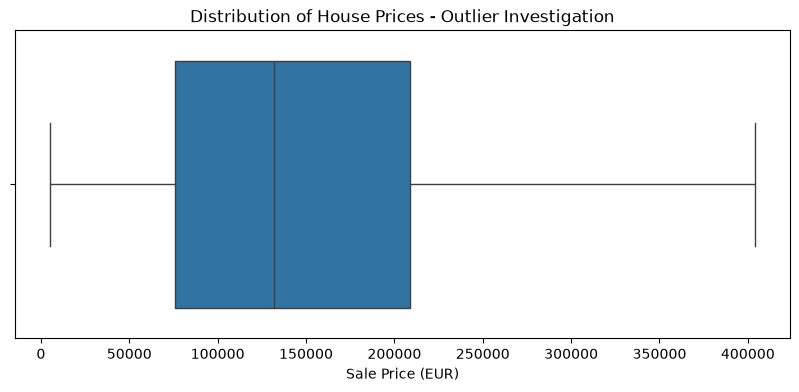

In [20]:
Q1 = df["price_eur"].quantile(0.25)
Q3 = df["price_eur"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR


outliers = df[(df["price_eur"] < lower_limit) |(df["price_eur"] > upper_limit)]

plt.figure(figsize=(10, 4))
sns.boxplot(x=df["price_eur"])
plt.title("Distribution of House Prices - Outlier Investigation")
plt.xlabel("Sale Price (EUR)")
plt.show()


The graph shows that the property price is not normally distributed. Skewness is positive; the distribution is right-skewed.

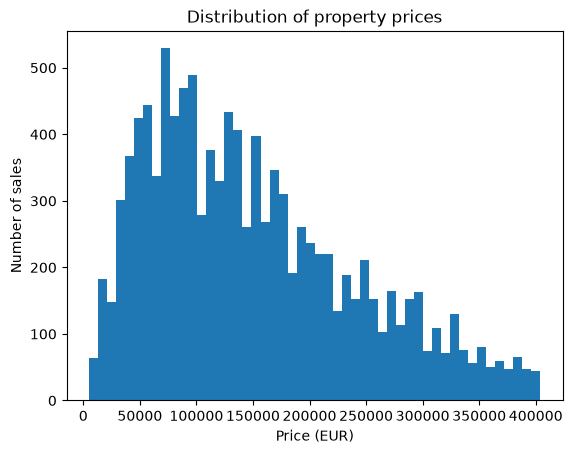

In [21]:
import matplotlib.pyplot as plt

plt.hist(df["price_eur"], bins=50)
plt.title("Distribution of property prices")
plt.xlabel("Price (EUR)")
plt.ylabel("Number of sales")
plt.show()

The feature property_size has about 93.6% of missing values, which is why it was not considered a reliable predictor.

In [22]:
missing = (df.isnull().mean() * 100).round(1).sort_values(ascending=False)
display(missing.to_frame(name="% missing"))

,% missing
property_size,93.6
eircode,71.2
date_of_sale,0.0
county,0.0
address,0.0
price_eur,0.0
not_full_market_price,0.0
vat_exclusive,0.0
description,0.0


# 4. Exploratory data analysis

## 4.1 Distribution of Property Sale Prices

The histogram reveals that most of the home sales values are between €50,000 and €150,000 with the maximum frequency between €70,000 and €90,000. The distribution looks to be positively skewed (right skewed) as there is a longer tail toward greater property prices. This shows that most properties are sold at relatively lower prices while few properties are sold at very higher prices. This implies that the distribution is not symmetric.

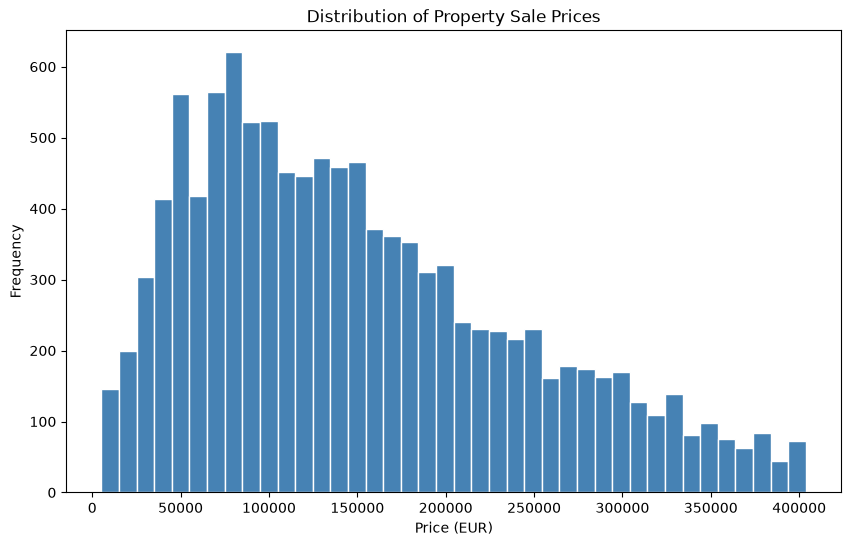

In [23]:
plt.figure(figsize=(10, 6))

plt.hist( df["price_eur"], bins=40, color="steelblue", edgecolor="white")

plt.title("Distribution of Property Sale Prices")
plt.xlabel("Price (EUR)")
plt.ylabel("Frequency")

plt.show()

## 4.2 Median Property Price per Year
 In the graph you can see that property prices are generally rising over time.

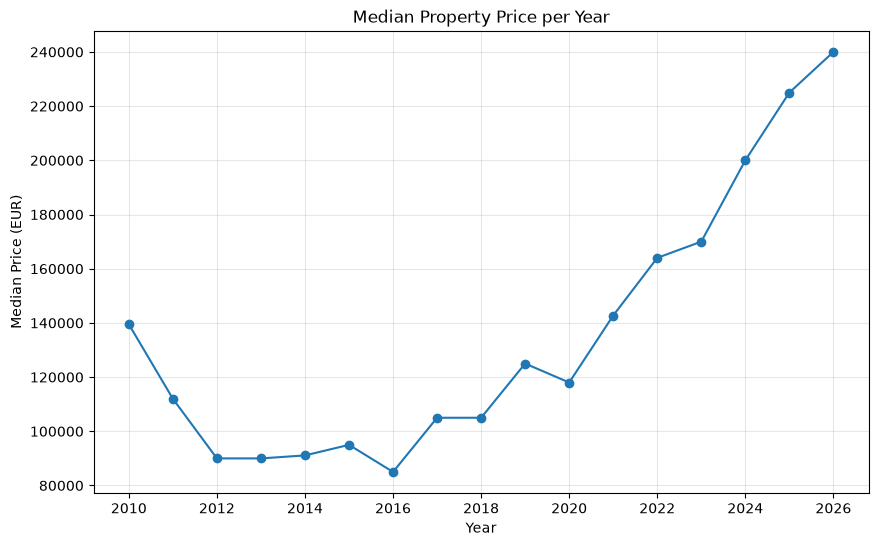

In [24]:
df["year"] = pd.to_datetime(df["date_of_sale"],errors="coerce").dt.year

plt.figure(figsize=(10, 6))

df.groupby("year")["price_eur"].median().plot( marker="o")

plt.title("Median Property Price per Year")
plt.xlabel("Year")
plt.ylabel("Median Price (EUR)")
plt.grid(alpha=0.3)
plt.show()

## 4.3. New vs Second-Hand Property Prices

The boxplot shows that the median price of sale for new properties is greater than the median price of sale for second-hand houses. 

<Figure size 1000x600 with 0 Axes>

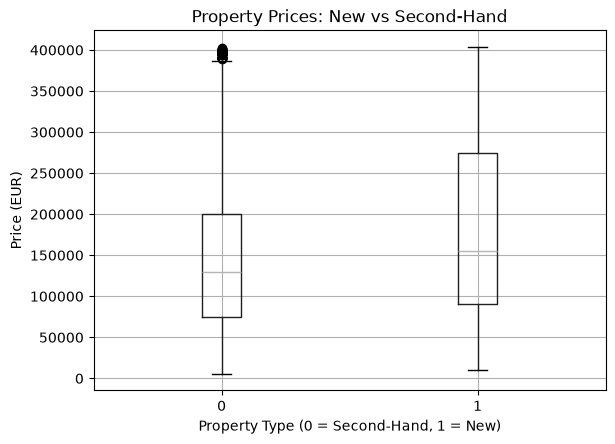

In [25]:
df["is_new"] = df["description"].str.contains("New|Nua", case=False,regex=True).astype(int)

plt.figure(figsize=(10, 6))

df.boxplot(column="price_eur", by="is_new")

plt.title("Property Prices: New vs Second-Hand")
plt.suptitle("")
plt.xlabel("Property Type (0 = Second-Hand, 1 = New)")
plt.ylabel("Price (EUR)")

plt.show()

## 4.4. Median price per locality

Median prices vary significantly by locality. The highest medians are in coastal and tourist areas such as Drumcliff (€252,000), Strandhill (€242,291) and Rosses Point (€226,000).

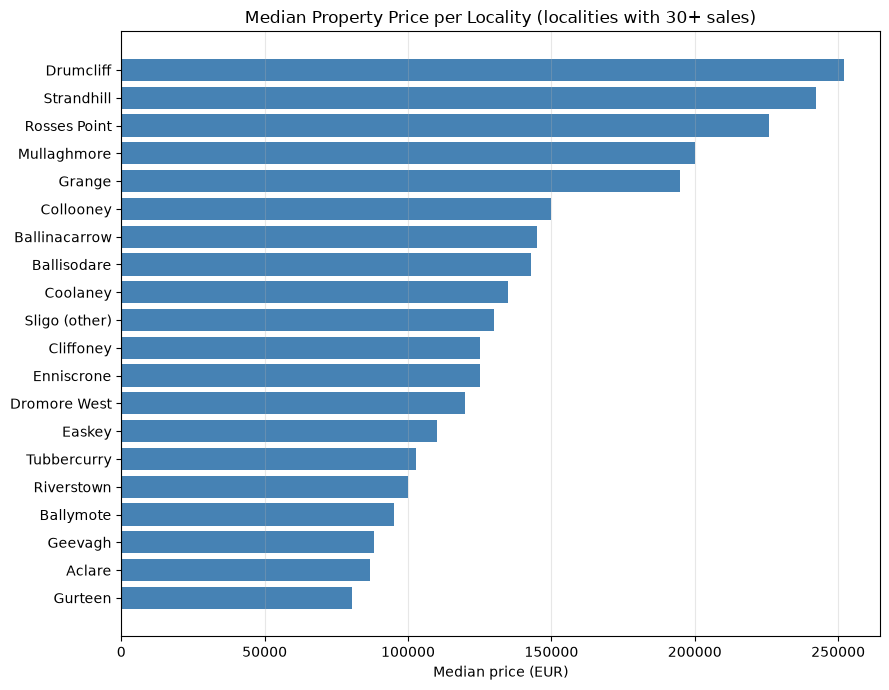

In [26]:
towns = [
    "collooney", "strandhill", "tubbercurry", "ballymote",
    "enniscrone", "rosses point", "grange", "easkey",
    "riverstown", "ballisodare", "dromore west", "coolaney",
    "ballinacarrow", "mullaghmore", "cliffoney", "gurteen",
    "bunninadden", "geevagh", "aclare", "culfadda",
    "achonry", "drumcliff"]


def get_locality(addr):

    if pd.isna(addr):
        return "Unknown"

    a = str(addr).lower()

    for t in towns:
        if t in a:
            return t.title()

    return "Sligo (other)"
    
df["locality"] = df["address"].apply(get_locality)

locality_stats = df.groupby("locality")["price_eur"].agg(["median", "count"])
locality_stats = locality_stats[locality_stats["count"] >= 30].sort_values("median")

plt.figure(figsize=(9, 7))
plt.barh(locality_stats.index, locality_stats["median"], color="steelblue")
plt.title("Median Property Price per Locality (localities with 30+ sales)")
plt.xlabel("Median price (EUR)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In the graph below, we can see that location matters a lot. Median prices in County Sligo range from about €55k to almost €250k. The cheapest localities are Bunninadden, Culfadda, Gurteen and Aclare, while the most expensive are Drumcliff, Strandhill, Rosses Point and Mullaghmore. Because prices overlap heavily between localities, it is difficult to predict the price from locality alone. There are also many outliers, and prices stop at about €400k because the 5% most expensive sales were removed.

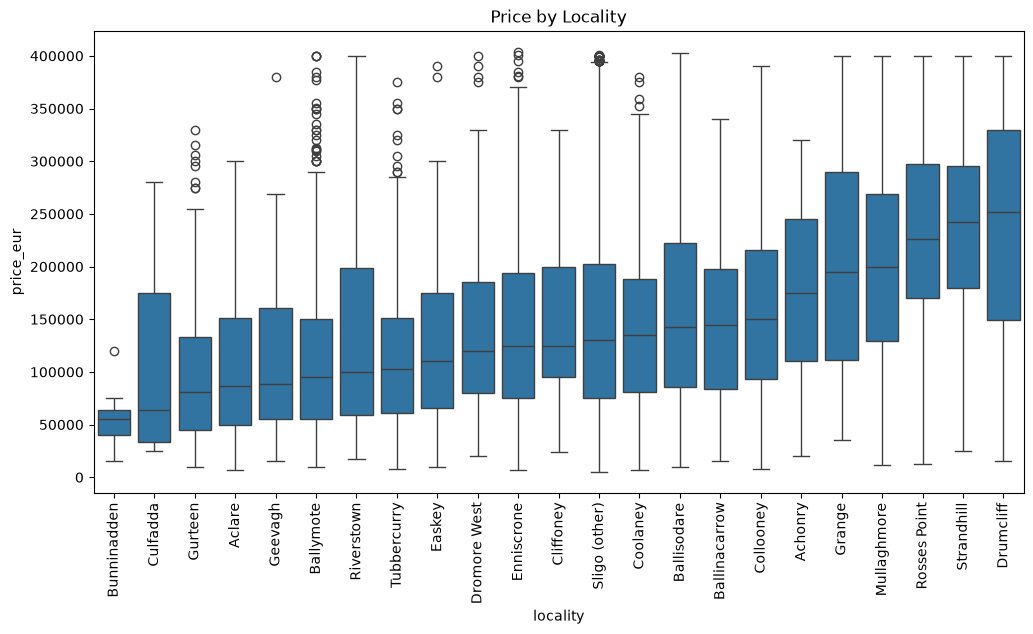

In [27]:
order = df.groupby('locality')['price_eur'].median().sort_values().index
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='locality', y='price_eur', order=order)
plt.xticks(rotation=90)
plt.title('Price by Locality')
plt.show()

## 4.5.Numeric Feature Correlation Heatmap
A strong correlation (0.98) was found between vat_exclusive and is_new, indicating redundancy, since VAT applies only to new properties. Year showed the strongest correlation with price (0.38), meaning that prices rise over the years, while all other correlations were weak.

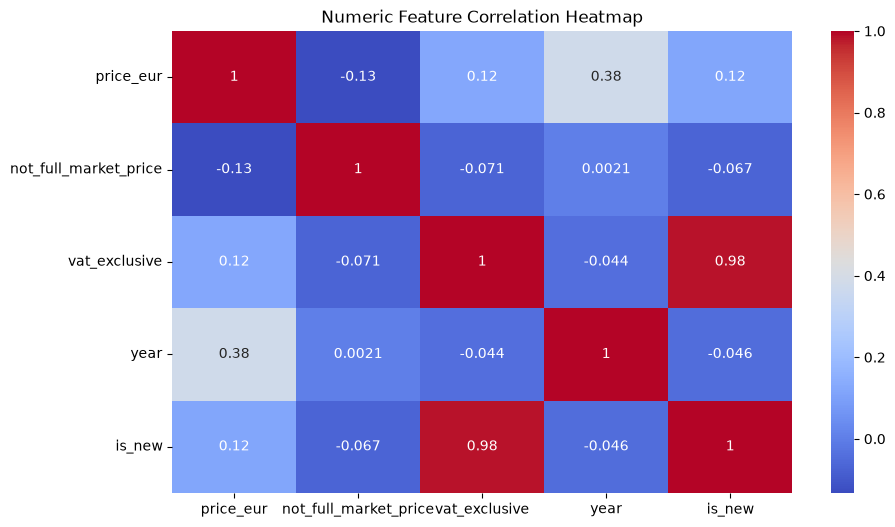

In [28]:
cat_cols = df.select_dtypes(["object", "str"]).columns
num_cols = df.select_dtypes(exclude='object').columns

corr_matrix = df[num_cols].corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=True)
plt.title("Numeric Feature Correlation Heatmap")
plt.show()

## 4.6 House Prices by Year

In general, house prices have been rising over the years. Prices remained fairly stable between 2012 and 2016, but have accelerated since 2021.

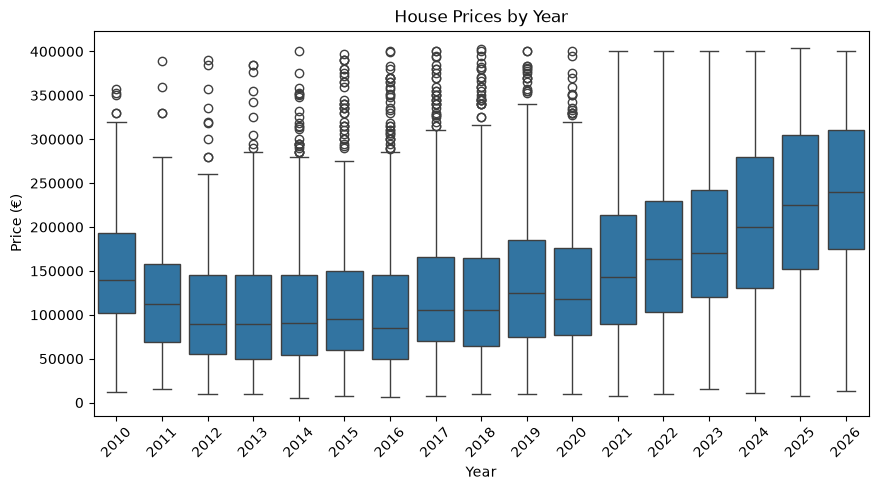

In [53]:
df["date_of_sale"] = pd.to_datetime(df["date_of_sale"])

df["year"] = df["date_of_sale"].dt.year

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="year",
    y="price_eur"
)

plt.title("House Prices by Year")
plt.xlabel("Year")
plt.ylabel("Price (€)")
plt.xticks(rotation=45)

plt.show()

# 5. Feature Selection and Preparation

In [29]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include=["object", "str"]).columns

print("Numerical columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))

Numerical columns: 3
Categorical columns: 7


The target variable selected was price_eur, as the objective of this project is to predict property sale prices in County Sligo.

In [30]:
X = df[['not_full_market_price', 'vat_exclusive', 'description',
        'property_size', 'date_of_sale', 'address']].copy()
y = df['price_eur']

print(X.shape, y.shape)

(11163, 6) (11163,)


In [31]:
print(X.columns.tolist())

['not_full_market_price', 'vat_exclusive', 'description', 'property_size', 'date_of_sale', 'address']


The text variable description (stored as str) was converted into a binary variable is_new (1 = new property, 0 = second-hand), so that it could be used by the models. The original column was then dropped.

In [32]:
# Convert the text description into a binary feature:
# 1 = new property ("New" or Irish "Nua"), 0 = second-hand
# na=False treats missing descriptions as 0 instead of raising an error
X["is_new"] = X["description"].str.contains("New|Nua", case=False, regex=True, na=False).astype(int)

X = X.drop(columns=["description"])


Property size: As it was stored as text, convert the text into categories. The original property size specifications were compressed into four simple categories: < 38 m², 38–125 m², > 125 m², and unknown. This change simplified the original text feature and made it easier for the machine learning algorithms to use. Missing values were kept as a “unknown” category, rather than deleting the relevant records as it was to many.

In [33]:

def size_cat(s):

    if pd.isna(s):
        return "unknown"

    s = str(s).lower()

    if "less than 38" in s:
        return "lt38"

    elif "38" in s and "125" in s:
        return "38to125"

    elif "125" in s:
        return "gt125"

    return "unknown"


X["size_cat"] = X["property_size"].apply(size_cat)

X = X.drop(columns=["property_size"])

As the models only work with numbers had to turn the sale date (stored as str)into two numeric columns, year and month, then drops the original date column. Any missing values (including dates that could not be read) are filled with the median year and month.

In [34]:
dates = pd.to_datetime(X["date_of_sale"],errors="coerce")

X["year"] = dates.dt.year
X["month"] = dates.dt.month

X = X.drop(columns=["date_of_sale"])

X["year"] = X["year"].fillna(X["year"].median())
X["month"] = X["month"].fillna(X["month"].median())

Addresses (stored as str) were grouped into 22 Sligo localities by matching town names in the address text, with remaining addresses labelled ‘Sligo (other)

In [35]:
X["locality"] = X["address"].apply(get_locality)

X = X.drop(columns=["address"])

Categorical variables (size category, locality, not full market price and VAT exclusive) were converted to binary indicator columns using one-hot encoding, because the models require numerical input. 
One-hot encoding was used because the categorical variables have no natural order, and label encoding would introduce an artificial ranking that can mislead models such as linear regression.

In [36]:
# One-hot encoding: each category becomes its own 0/1 column;
# because the models only accept numeric input;
# dtype=int gives 0/1 instead of True/False
X = pd.get_dummies( X,columns=["size_cat","locality","not_full_market_price","vat_exclusive"],dtype=int)


After applying one-hot enconding from 6 features we have now 34.

In [37]:

print("Tree models:", X.shape)
print("Linear Regression:", X.shape)

print("Missing values:", X.isnull().sum().sum())
print("Target missing values:", y.isnull().sum())


Tree models: (11163, 34)
Linear Regression: (11163, 34)
Missing values: 0
Target missing values: 0


After converting numerical year categories into separate binary columns, so your machine learning models can use them, the number of features are 49.

In [38]:

X = pd.get_dummies( X, columns=["year"], drop_first=True, dtype=int)

print("Tree models:", X.shape)
print("Linear Regression:", X.shape)


Tree models: (11163, 49)
Linear Regression: (11163, 49)


All models have the same number of features and observations.

In [39]:

feature_sets = {"Linear Regression": X, "Decision Tree": X, "Random Forest": X}

for model, features in feature_sets.items():
    print(model, features.shape)


Linear Regression (11163, 49)
Decision Tree (11163, 49)
Random Forest (11163, 49)


In [40]:

print("X information:")
print(X.info())

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nTarget missing values:")
print(y.isnull().sum())

print("\nTarget statistics:")
print(y.describe())


X information:
<class 'pandas.DataFrame'>
Index: 11163 entries, 40 to 807833
Data columns (total 49 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   is_new                       11163 non-null  int64
 1   month                        11163 non-null  int32
 2   size_cat_38to125             11163 non-null  int64
 3   size_cat_gt125               11163 non-null  int64
 4   size_cat_lt38                11163 non-null  int64
 5   size_cat_unknown             11163 non-null  int64
 6   locality_Achonry             11163 non-null  int64
 7   locality_Aclare              11163 non-null  int64
 8   locality_Ballinacarrow       11163 non-null  int64
 9   locality_Ballisodare         11163 non-null  int64
 10  locality_Ballymote           11163 non-null  int64
 11  locality_Bunninadden         11163 non-null  int64
 12  locality_Cliffoney           11163 non-null  int64
 13  locality_Collooney           11163 non-null  

In [41]:
print(df["not_full_market_price"].value_counts(dropna=False))
print(df["vat_exclusive"].value_counts(dropna=False))
print(df["description"].value_counts(dropna=False))
print(df["property_size"].value_counts(dropna=False))

not_full_market_price
False    10765
True       398
Name: count, dtype: int64
vat_exclusive
False    9741
True     1422
Name: count, dtype: int64
description
Second-Hand Dwelling house /Apartment    9703
New Dwelling house /Apartment            1460
Name: count, dtype: int64
property_size
NaN                                                                  10452
greater than or equal to 38 sq metres and less than 125 sq metres      502
greater than 125 sq metres                                              97
less than 38 sq metres                                                  83
greater than or equal to 125 sq metres                                  29
Name: count, dtype: int64


# 6. Model Evaluation Using Different Training Splits

To investigate how the amount of training data affects model performance, three different training proportions (5%, 15% and 25% of the dataset) were selected. Five-fold cross-validation was then applied to each training sample to evaluate and compare the performance of the models.

## 6.1 Models and visualization
The three models were chosen to compare the approaches of house price prediction, from a simple statistical model to more complex machine learning algorithms. Linear Regression is used as a benchmark for comparison, and Decision Tree and Random Forest are able to learn more complicated patterns in the dataset. I can assess the performance of each model by using metrics like MAE, RMSE and R^2 to understand which model gives most accurate predictions for the property price dataset.

In [42]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}


The models will be split into three training splits: 5%, 15%, and 25%, and the accuracy in each stage will be analysed. 

In [43]:
#the three training proportions to compare (5%, 15% and 25% of the data)
# 5-fold cross-validation on the TRAINING data only
split_sizes = [0.05, 0.15, 0.25]
results = []



for size in split_sizes:
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=size, random_state=42)

    for name, model in models.items():   
        cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")

        
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        results.append({
            "Train size": f"{int(size * 100)}%",       # R² on the data the model was trained on (high = it memorised the training data)
            "Train_R2": r2_score(y_train, model.predict(X_train)),  # Mean R² across the 5 CV folds (how well it generalises inside the training set)
            "CV_R2": cv_scores.mean(),        # R² on the unseen test set (the real measure of generalisation)
            "Test_R2": r2_score(y_test, pred),         # Mean absolute error in euros (average size of the mistake)
            "Test_MAE": mean_absolute_error(y_test, pred),    # Root mean squared error in euros (penalises large mistakes more than MAE)
            "Test_RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        })

results_df = pd.DataFrame(results)
results_df.round(3)

,Train size,Train_R2,CV_R2,Test_R2,Test_MAE,Test_RMSE
0,5%,0.420,0.294,0.275,60270.573,78176.183
1,5%,0.834,-0.274,-0.053,71843.939,94209.745
2,5%,0.767,0.133,0.193,63409.837,82489.733
3,15%,0.407,0.369,0.326,58515.512,75470.924
4,15%,0.739,0.024,0.062,67763.525,89024.615
5,15%,0.699,0.252,0.249,61212.453,79701.992
6,25%,0.376,0.348,0.339,58239.508,74534.447
7,25%,0.690,0.136,0.096,66506.917,87174.467
8,25%,0.656,0.281,0.263,60337.716,78693.562


The graph shows that more information the model have bigger the Test R2 gets.  

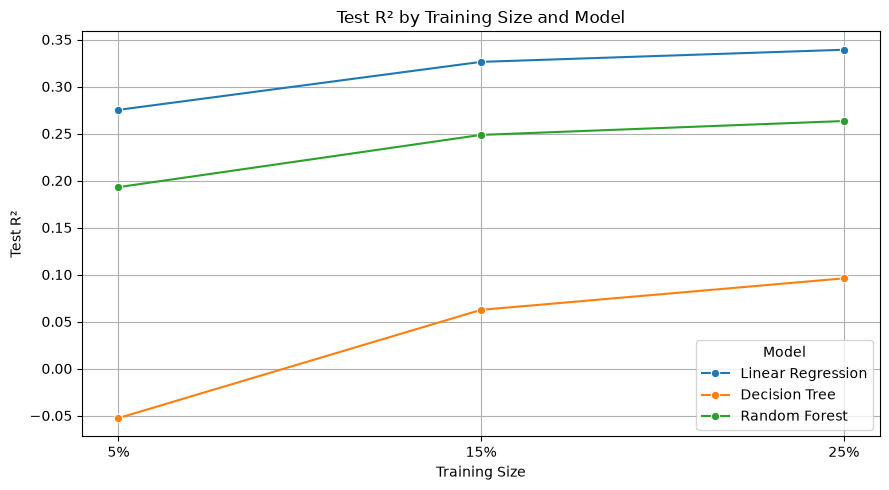

In [44]:
results_df["Model"] = ["Linear Regression", "Decision Tree", "Random Forest"] * 3
split_order = ["5%", "15%", "25%"]

plt.figure(figsize=(9, 5))

sns.lineplot(data=results_df,x="Train size", y="Test_R2", hue="Model", marker="o", sort=False)

plt.xticks(range(len(split_order)), split_order)
plt.title("Test R² by Training Size and Model")
plt.xlabel("Training Size")
plt.ylabel("Test R²")
plt.grid(True)
plt.tight_layout()
plt.show()

The 5 folds cross validation proving that linear regression is more stable than the others.

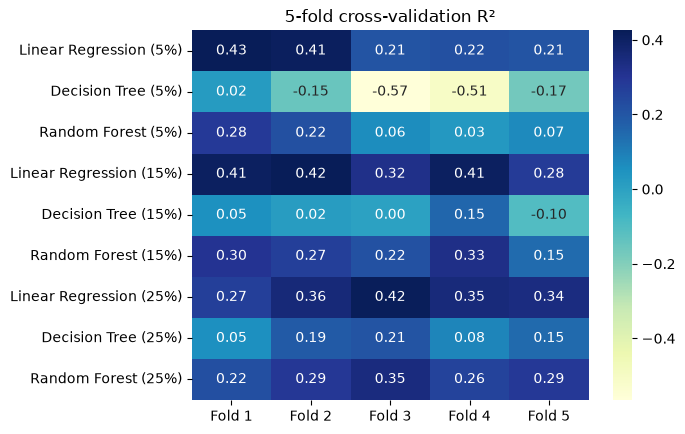

In [45]:
rows = {}

for size in [0.05, 0.15, 0.25]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=size, random_state=42)

    for name, model in models.items():
        
        rows[f"{name} ({int(size*100)}%)"] = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")


cv_folds = pd.DataFrame(rows, index=["Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"]).T

sns.heatmap(cv_folds, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("5-fold cross-validation R²")
plt.show()

# 7 – Hyperparameter Tuning Using GridSearchCV.
GridSearchCV was applied to the 25% training split (2,790 observations) because it has the most training data and the most stable CV in the tree models.

In [46]:
# Hyperparameter values to try for each model
# Linear Regression has almost nothing to tune: with or without an intercept
# max_depth limits how deep the tree grows (smaller = simpler, less overfitting)
 # min_samples_leaf = minimum rows in a leaf (larger = smoother predictions)


param_grids = {
    "Linear Regression": {"fit_intercept": [True, False]},   
    "Decision Tree": {
        "max_depth": [3, 5, 10, None],
        "min_samples_leaf": [1, 5, 10, 20],
    },
    "Random Forest": {
        "n_estimators": [50, 100], # Number of trees in the forest
        "max_depth": [5, 10, None],  
        "min_samples_leaf": [1, 5, 10],
    },
}

In [47]:
tuned_models = {}     # stores the best version of each model
tuning_rows = []

for name, model in models.items():
    grid = GridSearchCV(model, param_grids[name], cv=5, scoring="r2")
    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    tuned_models[name] = best_model

    tuning_rows.append({
        "Model": name,
        "Best parameters": grid.best_params_,
        "Best CV_R2": grid.best_score_,
        "Test_R2": r2_score(y_test, best_model.predict(X_test)),
    })

tuning_df = pd.DataFrame(tuning_rows)
tuning_df

,Model,Best parameters,Best CV_R2,Test_R2
0,Linear Regression,{'fit_intercept': True},0.348397,0.339116
1,Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 10}",0.276747,0.288994
2,Random Forest,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_es...",0.325695,0.316620


# 8. Comparison of the tuned models

Bigger the gap= overfitting. 

In [48]:
final_rows = []
for name, model in tuned_models.items():
    pred = model.predict(X_test)
    train_r2 = r2_score(y_train, model.predict(X_train))
    test_r2 = r2_score(y_test, pred)
    final_rows.append({
        "Model": name,
        "Train_R2": train_r2,
        "Test_R2": test_r2,
        "Gap (Train - Test)": train_r2 - test_r2,      # big gap = overfitting
        "Test_MAE": mean_absolute_error(y_test, pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    })

final_table = pd.DataFrame(final_rows).set_index("Model")
final_table.round(3)

,Train_R2,Test_R2,Gap (Train - Test),Test_MAE,Test_RMSE
Model,,,,,
Linear Regression,0.376,0.339,0.037,58239.508,74534.447
Decision Tree,0.367,0.289,0.078,60812.662,77309.187
Random Forest,0.453,0.317,0.136,59334.155,75792.397


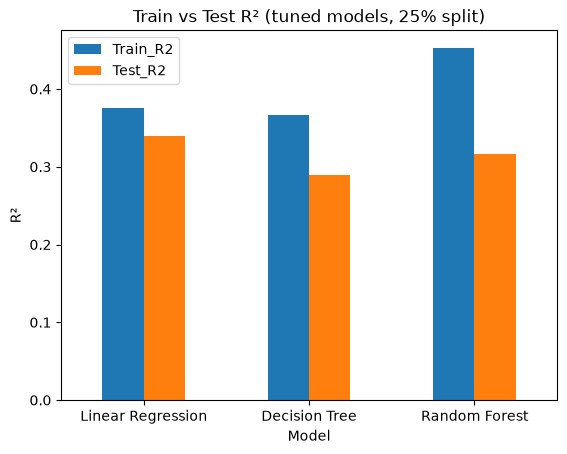

In [49]:
final_table[["Train_R2", "Test_R2"]].plot(kind="bar")
plt.title("Train vs Test R² (tuned models, 25% split)")
plt.ylabel("R²")
plt.xticks(rotation=0)
plt.show()

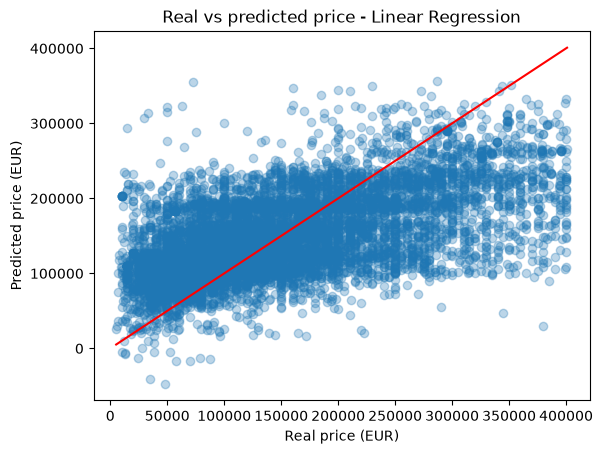

Best model: Linear Regression


In [50]:
best_name = final_table["Test_R2"].idxmax()
best_pred = tuned_models[best_name].predict(X_test)

plt.scatter(y_test, best_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")   # perfect prediction line
plt.title(f"Real vs predicted price - {best_name}")
plt.xlabel("Real price (EUR)")
plt.ylabel("Predicted price (EUR)")
plt.show()

print("Best model:", best_name)

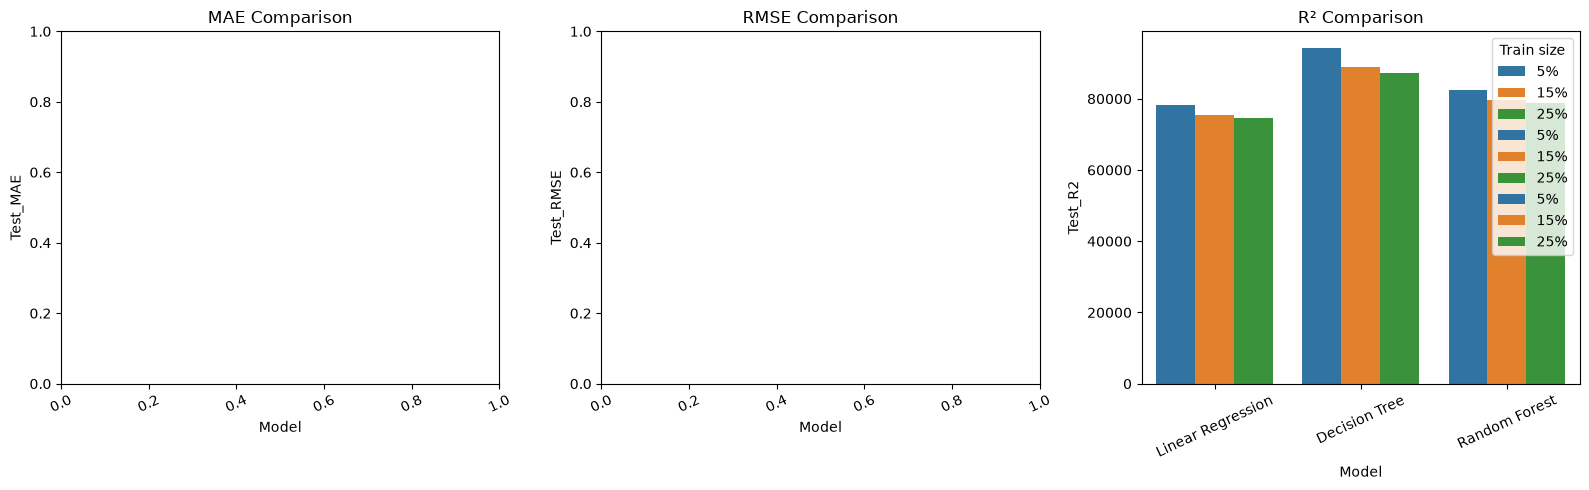

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["Test_MAE", "Test_RMSE", "Test_R2"]
titles = ["MAE Comparison", "RMSE Comparison", "R² Comparison"]

for ax, metric, title in zip(axes, metrics, titles):

    sns.barplot( data=results_df,  x="Model",  y=metric,  hue="Train size",   )

    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

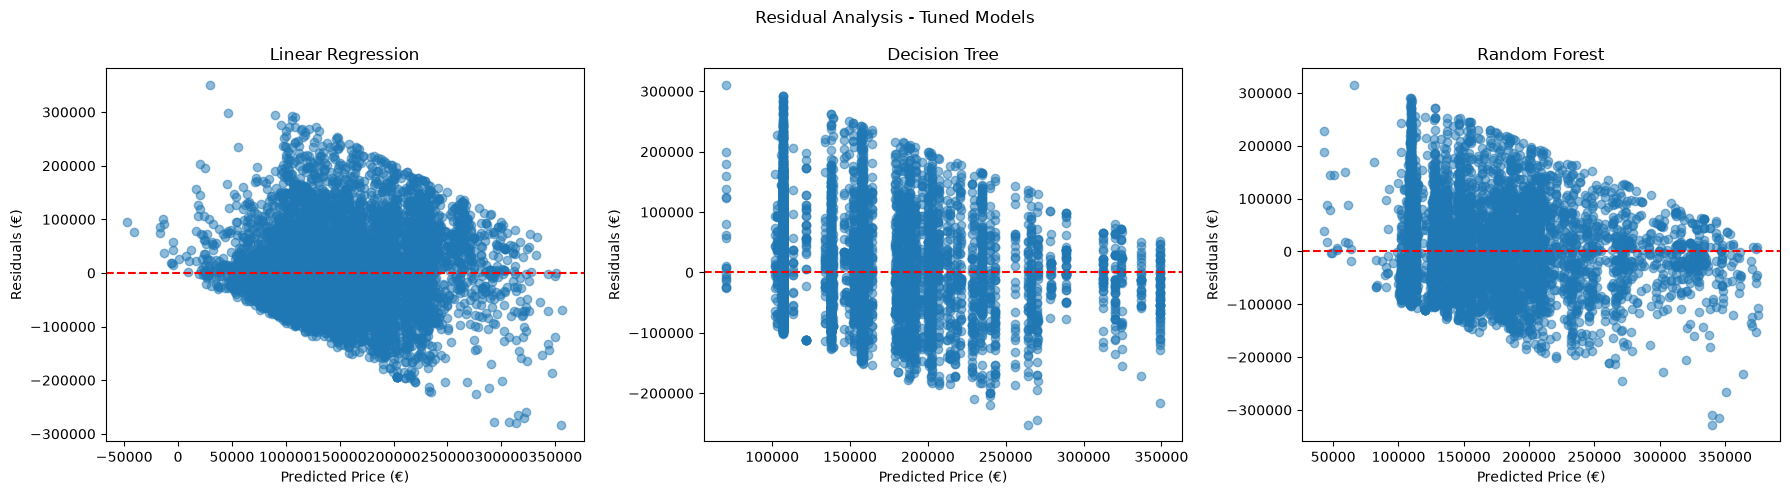

In [60]:
models = tuned_models

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test)

    residuals = np.array(y_test) - y_pred

    ax.scatter(y_pred, residuals, alpha=0.5)

    ax.axhline(y=0, color="red", linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("Predicted Price (€)")
    ax.set_ylabel("Residuals (€)")

plt.suptitle("Residual Analysis - Tuned Models")
plt.tight_layout()
plt.show()

# 8.1 Feature importance
The Linear Regression was selected as the final model because, among the three models, it achieved the highest R² on the test set after hyperparameter tuning.
The graph below shows the 10 features with the largest coefficients in the tuned Linear Regression. The coefficients of the tuned Linear Regression indicate that location and time are the main factors that influence price. The negative prices may be because, at that time, the market was still recovering from the 2008- 2009 crisis.

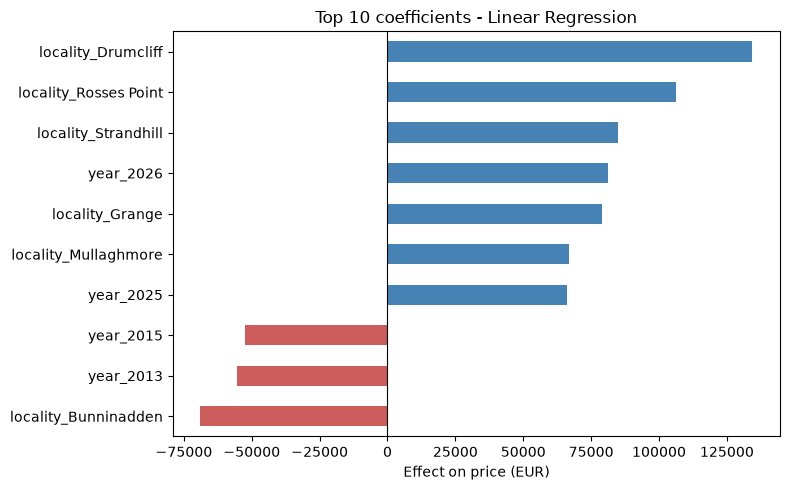

locality_Drumcliff       134380.0
locality_Rosses Point    106133.0
locality_Strandhill       84751.0
year_2026                 81270.0
locality_Grange           79162.0
locality_Bunninadden     -68924.0
locality_Mullaghmore      66884.0
year_2025                 66236.0
year_2013                -55446.0
year_2015                -52447.0
dtype: float64

In [51]:
# Coefficients of the tuned Linear Regression (effect on price in EUR)
lr = tuned_models["Linear Regression"]
coefs = pd.Series(lr.coef_, index=X.columns)

top10_lr = coefs.reindex(coefs.abs().sort_values(ascending=False).head(10).index)

plt.figure(figsize=(8, 5))
colors = ["steelblue" if c > 0 else "indianred" for c in top10_lr.sort_values()]
top10_lr.sort_values().plot(kind="barh", color=colors)
plt.title("Top 10 coefficients - Linear Regression")
plt.xlabel("Effect on price (EUR)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

top10_lr.round(0)

## 8.2 Predict price using linear regression
Based on the model that achieved the R2 after tuning, the predicted price for a house that will be sold in december/2026, with a size between 38 and 125 m2, is 286,209 euros. It is important to remember that the model explains about 35% of why prices differ from one sale to another. The relatively low R² is probably due to the limited information in the register: important price drivers such as the number of bedrooms, property condition and exact location are not recorded, and property size is missing for about 94% of the sales. Moreover, models were trained on small subsets of data (5% to 25% ).

In [52]:
model = tuned_models["Linear Regression"]

def make_house(**features):
    house = pd.DataFrame(0, index=[0], columns=X.columns)

    for col, value in features.items():
        if col not in X.columns:
            raise KeyError(f"Coluna '{col}' does not exist in X")
        house[col] = value

    return house


house1 = make_house(is_new=0,month=12,year_2026=1,locality_Strandhill=1, size_cat_38to125=1, not_full_market_price_False=1,vat_exclusive_False=1)


price = model.predict(house1)[0]

print(f"Predicted price: EUR {price:,.0f}")



Predicted price: EUR 286,209
